# F1 Pit-Stop Strategy Simulator: Safety-Car Uncertainty at Singapore

**Summary.** This notebook simulates a 62-lap Formula 1 race at Singapore to compare one-stop, two-stop and *pit-if-neutralised* tyre strategies when Safety Car (SC) and Virtual Safety Car (VSC) periods occur at random. Tyre wear follows a fuel-coupled, self-accelerating ODE solved with **RK4**. Track status follows a lap-wise **Markov chain** with a phase-type minimum Safety-Car length. Pit losses are derived from pit-lane geometry. Stationary crew times and lap noise are generated with **inverse-transform and Box–Muller** samplers. Strategies are compared with **two-stage Monte Carlo using common random numbers (CRN)**, reporting 95% confidence intervals for paired race-time differences. The simulator is verified against closed-form ODE solutions, a deterministic benchmark with a derived optimum, the Markov chain's stationary distribution, and an **exact expected-race-time formula** that the Monte Carlo must reproduce.

*Run with Runtime → Run all. No data downloads are needed. Seeds are fixed and printed. Parameters marked "assumed" are documented in §3 and tested in the sensitivity study.*

In [1]:
# Install / check dependencies (pre-installed on Colab; pins match requirements.txt)
!pip install -q "numpy>=1.24" "matplotlib>=3.7"

In [2]:
import os, math, time
import numpy as np
import matplotlib.pyplot as plt

SEED = 20251005                      # master seed for every experiment (printed below)
FIG_DIR = "../figures" if os.path.isdir("../figures") else "figures"   # repo layout or Colab
os.makedirs(FIG_DIR, exist_ok=True)
print("numpy", np.__version__, "| master seed", SEED, "| figures ->", FIG_DIR)

numpy 2.5.3 | master seed 20251005 | figures -> ../figures


## 2. Problem and question

Formula 1 teams trade the pace of fresh tyres against the time lost in the pit lane. A stop taken under SC or VSC is cheaper, because cars on track slow down while the pit lane keeps its speed limit. Singapore is the extreme case: every race from 2008 to 2023 had at least one Safety Car, but 2024 and 2025 had none. The 2025 pit-lane speed limit rise (60 → 80 km/h) also cut the pit loss by roughly 6 s.

**Question.** For a 62-lap Singapore race, how does the expected race-time difference (with 95% CI) between the best one-stop, two-stop and pit-if-neutralised strategies change as the per-lap SC onset probability $P_{GS}$ varies, and at what $P_{GS}$ does the preferred strategy switch?

**Scope.** One car, no traffic or positions (objective: expected race time); dry race; no red flags; no refuelling.

## 3. Model, assumptions and equations

### 3.1 Assumptions
| # | Assumption | Why | Unlocks |
|---|---|---|---|
| H1 | Lap-discrete time, fixed 62 laps, no red flags | Status, stops and tyre life are logged per lap | finite-horizon DTMC |
| H2 | Track status is exogenous (independent of our strategy) | one car barely affects incident risk | valid CRN pairing |
| H3 | Markov and time-homogeneous after lap 1; separate lap-1 onset | lap-1 incidents are over-represented | exact marginals via $P^\ell$ |
| H4 | SC lasts at least $m$ laps (phase-type), then geometric | real SCs last ≈2–8 laps | closed-form duration law |
| H5 | VSC/SC end in Green | escalations are rare | renewal-reward stationary law |
| H6 | Under VSC/SC lap time $=k_s t_0$, set by the neutralisation | cars follow the SC / VSC delta | SC laps cancel in paired differences |
| H7 | Green lap time is additive and separable | standard in race simulation | linearity of expectation |
| H8 | Smooth, self-accelerating tyre wear ODE | worn tyres overheat; no cliff inside a stint | closed form, convex stint cost, meaningful RK4 order |
| H9 | Pit lane at constant limit speed; bypassed section slows by $k_s$ | pit limiter | derived $\alpha_s$ |
| H10 | i.i.d. Gaussian lap noise, i.i.d. shifted-lognormal crew time | standard input models | CLT, exact sampler tests |
| H11 | Risk-neutral objective (expected race time) | single car, no positions | well-posed comparison |
| H12 | Race time is non-decreasing in every common random input | true by construction | CRN cannot increase variance |
| H13 | Stage 2 uses fresh seeds, shortlist fixed beforehand | avoids winner's-curse bias | unbiased final estimates |

### 3.2 Tyre wear and fuel (numerical ODE solvers)
Fuel mass on race lap $\ell$: $m(\ell)=m_0-b(\ell-1)$ [kg]. Tyre degradation $w$ [s] with tyre age $a$ [laps] in a stint starting on lap $s$:
$$\frac{dw}{da}=k_c\,(1+\beta\,m(s+a))\,(1+\eta\,w)\,\varphi(\text{status}),\qquad w(0)=0,$$
with $\varphi=1,\ \varphi_V,\ \varphi_S$ for Green, VSC, SC. For constant $\varphi$ the equation separates, giving the exact solution used for verification:
$$w(a)=\frac{e^{\eta k_c\varphi A(a)}-1}{\eta},\qquad A(a)=\big(1+\beta(m_0-b(s-1))\big)a-\tfrac{\beta b}{2}a^2 .$$
The simulator integrates one lap per RK4 step (status, and hence $\varphi$, is constant within a lap):
$$y_{n+1}=y_n+\tfrac{h}{6}(k_1+2k_2+2k_3+k_4),\qquad \text{global error }O(h^4).$$
Since the growth rate $\lambda=\eta k_c(1+\beta m)\approx 10^{-3}$ per lap, $|h\lambda|\ll 1$ and the scheme is stable at $h=1$ lap. *If $\eta=0$ the right-hand side depends only on $a$, and RK4 reduces to Simpson's rule and is exact. That is why $\eta>0$ is kept, so the order study is meaningful.*

### 3.3 Lap time
$$t_\ell=\begin{cases}t_0+\Delta_c+w_\ell+\gamma\,m(\ell)+\sigma\varepsilon_\ell, & \text{Green},\ \varepsilon_\ell\sim N(0,1)\\ k_s\,t_0, & \text{VSC/SC}\end{cases}$$
The fuel term $\gamma m(\ell)$ depends only on the lap, so it **cancels** in strategy differences. Fuel influences strategy only through the wear coupling $\beta$.

### 3.4 Track status (Markov chain)
States $\{G, V, SC_1,\dots,SC_m, SC^+\}$, where $SC_i\to SC_{i+1}$ with probability 1 and $SC_m, SC^+$ continue with $p_{SS}$. The SC duration is therefore $D=m+\text{Geom}$ with
$$E[D_S]=m+\frac{p_{SS}}{1-p_{SS}},\qquad \hat p_{SS}=\frac{\sum_i(D_i-m)}{\sum_i(D_i-m+1)}.$$
Long-run fractions by renewal-reward (H5), with onset probabilities $a=P_{GV}$ and $c=P_{GS}$:
$$\pi_G=\frac{1}{1+aE[D_V]+cE[D_S]},\quad \pi_V=aE[D_V]\pi_G,\quad \pi_S=cE[D_S]\pi_G .$$
The exact lap marginals are $p(\ell)=p(1)P^{\ell-1}$. Transition probabilities are estimated by maximum likelihood $\hat P_{ij}=n_{ij}/\sum_k n_{ik}$, with Beta credible intervals.

### 3.5 Pit loss (derived from geometry)
Green net transit loss: $\Delta T_G=T_{pit}-T_{bypass}$. Under neutralisation $s$ the bypassed section takes $k_sT_{bypass}$, but the speed-limited lane does not change:
$$\Delta T_s=(1-\alpha_s)\Delta T_G,\qquad \alpha_s=\frac{(k_s-1)\,T_{bypass}}{\Delta T_G}.$$
Total in-lap loss $=(1-\alpha_s)\Delta T_G + C$, with stationary time $C=c_0+e^{\mu+\sigma Z}$ (shifted lognormal, never scaled).

### 3.6 Analytic results used as verification references
* **One-stop optimum** (linear wear, $\eta=\beta=0$): $f(L)$ is convex, with $f''=k_1+k_2$, and
  $L^*=\dfrac{k_2N+(\Delta_2-\Delta_1)+(k_1-k_2)/2}{k_1+k_2}$.
* **One vs two stops, Green, equal stints:** a two-stop wins iff $kN^2/12>\Delta T_G+E[C]$.
* **Exact expectation for fixed strategies** (H2–H7, $\eta=\beta=0$, $\varphi=1$):
  $E[T]=\sum_\ell \big(p_G(\ell)\,g_\ell+p_V(\ell)k_Vt_0+p_S(\ell)k_St_0\big)+\sum_{L\in\mathcal L}\big(E[C]+\Delta T_G(1-\alpha_V p_V(L)-\alpha_S p_S(L))\big)$.

### 3.7 Monte Carlo with common random numbers
$\operatorname{Var}(T_B-T_A)=\operatorname{Var}T_A+\operatorname{Var}T_B-2\operatorname{Cov}(T_A,T_B)$. Race times are non-decreasing in the shared inputs (H12), so $\operatorname{Cov}\ge 0$ and CRN cannot increase the variance. Each source has its own random stream, so strategies with different numbers of stops still use the same scenario. CI: $\bar D\pm z\,s_D/\sqrt n$, with a Bonferroni-adjusted $z$ for multiple comparisons. The required sample size is $n\ge(z s_D/h^*)^2$.

### 3.8 Link to module topics
| Equation / algorithm | Module topic |
|---|---|
| Tyre-wear ODE, RK4 (and Euler/RK2 for comparison), error order $O(h^4)$ | Numerical ODE solvers (●) |
| Box–Muller normals; shifted-lognormal and DTMC sampling by inverse transform; KS tests | Input modelling and random variate generation (●) |
| Phase-type track-status chain, $p(\ell)=p(1)P^{\ell-1}$, $\pi=\pi P$, MLE of $P$ | Markov chains (DTMC) (○) |
| CRN paired differences, CIs, $O(N^{-1/2})$ convergence, sample-size formula | Monte Carlo and the law of large numbers (○) |

## 4. Implementation

The model code is below, one cell per component (source of truth: `src/f1sim.py` in the repository). Units: seconds [s], kilograms [kg], laps. Status codes: 0 Green, 1 VSC, 2 SC.

### 4.1 Module header and imports

In [3]:
"""
f1sim - single-car Formula 1 pit-stop strategy simulator.

Model summary (see the notebook for derivations):
  * Tyre wear ODE per lap, solved with RK4:
        dw/dl = k_c * (1 + beta * m(l)) * (1 + eta * w) * phi(status)        [s/lap]
  * Fuel mass m(l) = m0 - b * (l - 1)                                         [kg]
  * Green lap time  t = t0 + offset_c + w + gamma * m + eps,  eps ~ N(0, sigma^2)
  * VSC / SC lap time t = k_s * t0  (set by the neutralisation, not the car)
  * Track status: lap-wise DTMC over {Green, VSC, SC_1..SC_m, SC+} (phase-type
    minimum Safety-Car length), separate lap-1 onset probability.
  * Pit loss on the in-lap: (1 - alpha_s) * dT_G + crew time, with
    alpha_s = (k_s - 1) * T_bypass / dT_G derived from pit-lane geometry and
    crew time ~ shifted lognormal.
  * Common random numbers: independent streams for status, lap noise and crew
    time (numpy SeedSequence), so every strategy sees the same race scenario.

Units: time in seconds [s], fuel in kilograms [kg], laps are 1-based integers.
Status codes: 0 = Green, 1 = VSC, 2 = SC.
"""

import copy
import math
import time

import numpy as np

GREEN, VSC, SC = 0, 1, 2
STATUS_NAMES = ("Green", "VSC", "SC")
DRY_COMPOUNDS = ("SOFT", "MEDIUM", "HARD")

### 4.2 Parameters

In [4]:
def default_params():
    """Baseline parameter set for a 62-lap Singapore race.

    Every value is tagged in PARAM_SOURCES as 'literature', 'public data' or
    'assumed (calibrate with FastF1)'. Returns a new dict each call.
    """
    p = dict(
        n_laps=62,                      # [laps] 2025 Singapore race distance
        t0_s=96.0,                      # [s] base clean lap time, new tyre, no fuel
        offset_s={"SOFT": 0.0, "MEDIUM": 0.35, "HARD": 0.70},   # [s] compound pace offset
        k_s_per_lap={"SOFT": 0.100, "MEDIUM": 0.060, "HARD": 0.035},  # [s/lap] wear rate
        eta_per_s=0.02,                 # [1/s] wear self-acceleration (worn tyres wear faster)
        beta_per_kg=0.004,              # [1/kg] extra wear per kg of fuel
        m0_kg=100.0,                    # [kg] start fuel
        burn_kg_per_lap=1.6,            # [kg/lap] fuel burn
        gamma_s_per_kg=0.03,            # [s/kg] lap-time penalty per kg of fuel
        sigma_s=0.35,                   # [s] lap-time noise standard deviation
        # neutralisations
        k_vsc=1.40,                     # [-] VSC lap time / reference lap time
        k_sc=1.60,                      # [-] SC lap time / reference lap time
        phi_vsc=0.50,                   # [-] tyre-wear factor under VSC
        phi_sc=0.25,                    # [-] tyre-wear factor under SC
        # Markov chain (per-lap probabilities)
        p_gv=0.012,                     # [-] Green -> VSC onset
        p_gs=0.020,                     # [-] Green -> SC onset
        p_lap1_sc=0.15,                 # [-] SC onset on lap 1 (start incidents)
        p_vv=0.60,                      # [-] VSC persistence
        sc_min_laps=3,                  # [laps] minimum Safety-Car length m
        p_ss=0.50,                      # [-] SC persistence after the minimum
        # pit lane geometry (2025, 80 km/h limit)
        t_pit_s=36.0,                   # [s] pit entry -> exit through the lane (incl. no stop)
        t_bypass_s=15.0,                # [s] same section driven on track at racing speed
        # stationary crew time T = shift + exp(mu + sigma * Z)
        crew_shift_s=2.0,               # [s] physical minimum stop
        crew_mu=-0.51,                  # [-] log-scale location (median extra ~0.6 s)
        crew_sigma=0.50,                # [-] log-scale spread
        random=True,                    # False -> deterministic benchmark mode
    )
    return derive_alphas(p)


PARAM_SOURCES = {
    "n_laps": "public data (2025 race report)",
    "k_vsc, k_sc": "literature (Heilmeier et al. 2020, ~140% / ~160%)",
    "phi_vsc, phi_sc": "literature (Heilmeier et al. 2020, tyre ageing -50% / -75%)",
    "p_gs, p_gv, p_lap1_sc": "public data, rough (~7 SC onsets in ~370 laps, 2018-2025); calibrate with FastF1",
    "t_pit_s, t_bypass_s": "assumed (calibrate with FastF1 2025 PitInTime/PitOutTime)",
    "crew_*": "assumed, informed by published stationary times (DHL)",
    "t0_s, offset_s, k_s_per_lap, eta, beta, gamma, sigma": "assumed (calibrate with FastF1 clean stints)",
}


def derive_alphas(p):
    """Derive VSC/SC net-transit-loss reductions from pit-lane geometry.

    dT_G = T_pit - T_bypass; under neutralisation the bypassed section takes
    k_s * T_bypass while the speed-limited lane is unchanged, so
    alpha_s = (k_s - 1) * T_bypass / dT_G.  Modifies and returns p.
    """
    d_green = p["t_pit_s"] - p["t_bypass_s"]          # [s]
    assert d_green > 0, "pit lane must be slower than the track"
    p["dT_green_s"] = d_green
    p["alpha_vsc"] = (p["k_vsc"] - 1.0) * p["t_bypass_s"] / d_green
    p["alpha_sc"] = (p["k_sc"] - 1.0) * p["t_bypass_s"] / d_green
    return p


def with_params(p, **changes):
    """Return a deep copy of p with changes applied (alphas re-derived unless overridden)."""
    q = copy.deepcopy(p)
    q.update(changes)
    if "alpha_sc" not in changes and "alpha_vsc" not in changes:
        derive_alphas(q)
    return q

### 4.3 Numerical ODE solvers

In [5]:
def euler_solve(f, y0, t0, t1, n_steps):
    """Forward Euler: returns y(t1) after n_steps equal steps (global error O(h))."""
    h = (t1 - t0) / n_steps
    y = np.asarray(y0, dtype=float) if np.ndim(y0) else float(y0)
    t = t0
    for _ in range(n_steps):
        y = y + h * f(t, y)
        t += h
    return y


def rk2_solve(f, y0, t0, t1, n_steps):
    """Midpoint RK2: returns y(t1) (global error O(h^2))."""
    h = (t1 - t0) / n_steps
    y = np.asarray(y0, dtype=float) if np.ndim(y0) else float(y0)
    t = t0
    for _ in range(n_steps):
        k1 = f(t, y)
        k2 = f(t + h / 2, y + h / 2 * k1)
        y = y + h * k2
        t += h
    return y


def rk4_step(f, t, y, h):
    """One classical RK4 step of size h (local error O(h^5))."""
    k1 = f(t, y)
    k2 = f(t + h / 2, y + h / 2 * k1)
    k3 = f(t + h / 2, y + h / 2 * k2)
    k4 = f(t + h, y + h * k3)
    return y + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)


def rk4_solve(f, y0, t0, t1, n_steps):
    """Classical RK4: returns y(t1) (global error O(h^4)). y0 may be a float or array."""
    h = (t1 - t0) / n_steps
    y = np.asarray(y0, dtype=float) if np.ndim(y0) else float(y0)
    t = t0
    for _ in range(n_steps):
        y = rk4_step(f, t, y, h)
        t += h
    return y


def wear_rhs(p, compound, race_lap0, phi):
    """Right-hand side dw/da of the tyre-wear ODE for one lap.

    a is lap time-like (age measured in laps), race_lap0 is the race lap at
    a = 0 of this step, phi is the neutralisation factor. Works on arrays.
    Returns f(a, w) in [s/lap].
    """
    k = p["k_s_per_lap"][compound]
    beta, eta = p["beta_per_kg"], p["eta_per_s"]
    m0, b = p["m0_kg"], p["burn_kg_per_lap"]

    def f(a, w):
        fuel_kg = m0 - b * (race_lap0 - 1 + a)
        return k * (1.0 + beta * fuel_kg) * (1.0 + eta * w) * phi
    return f


def wear_closed_form(p, compound, stint_start_lap, age_laps, phi=1.0):
    """Exact solution of the wear ODE for constant phi (verification reference).

    w(a) = (exp(eta * k * phi * A(a)) - 1) / eta,
    A(a) = (1 + beta*(m0 - b*(s-1))) * a - beta*b*a^2/2.   Returns w [s].
    """
    k = p["k_s_per_lap"][compound]
    beta, eta = p["beta_per_kg"], p["eta_per_s"]
    m0, b = p["m0_kg"], p["burn_kg_per_lap"]
    a = np.asarray(age_laps, dtype=float)
    A = (1 + beta * (m0 - b * (stint_start_lap - 1))) * a - beta * b * a ** 2 / 2
    if eta == 0:
        return k * phi * A
    return (np.exp(eta * k * phi * A) - 1.0) / eta

### 4.4 Random variate generation

In [6]:
def box_muller(n, rng):
    """n standard normals from uniforms by the Box-Muller transform."""
    m = (n + 1) // 2
    u1 = 1.0 - rng.random(m)            # in (0, 1], avoids log(0)
    u2 = rng.random(m)
    r = np.sqrt(-2.0 * np.log(u1))
    z = np.concatenate([r * np.cos(2 * np.pi * u2), r * np.sin(2 * np.pi * u2)])
    return z[:n]


def box_muller_from_uniforms(u1, u2):
    """Box-Muller on given uniform arrays (u1 in (0, 1]). Returns (z1, z2)."""
    r = np.sqrt(-2.0 * np.log(u1))
    return r * np.cos(2 * np.pi * u2), r * np.sin(2 * np.pi * u2)


def crew_time_params(p):
    """(shift [s], mu, sigma) of the shifted-lognormal stationary crew time."""
    return p["crew_shift_s"], p["crew_mu"], p["crew_sigma"]


def crew_time_from_normal(z, p):
    """Map standard normals z to stationary crew times [s] (exact inverse transform)."""
    return p["crew_shift_s"] + np.exp(p["crew_mu"] + p["crew_sigma"] * z)


def sample_crew_time(n, p, rng):
    """n stationary crew times [s] from the shifted lognormal."""
    return crew_time_from_normal(box_muller(n, rng), p)

### 4.5 Track-status Markov chain

In [7]:
def lumped_matrix(p):
    """3x3 matrix over (Green, VSC, SC) with the same mean sojourn times.

    Used for reporting and for the stationarity check; the simulator uses the
    expanded phase-type chain from expanded_matrix().
    """
    a, c = p["p_gv"], p["p_gs"]
    mean_sc = sc_mean_duration(p)                       # [laps]
    r_sc = 1.0 / mean_sc
    return np.array([[1 - a - c, a, c],
                     [1 - p["p_vv"], p["p_vv"], 0.0],
                     [r_sc, 0.0, 1 - r_sc]])


def expanded_matrix(p):
    """Phase-type chain: states [G, V, SC_1..SC_m, SC+].

    SC_i -> SC_{i+1} with probability 1 enforces a minimum length m; SC_m and
    SC+ continue with p_ss or return to Green. Returns (P, collapse) where
    collapse[i] maps an expanded state to 0/1/2.
    """
    m = int(p["sc_min_laps"])
    n = 2 + m + 1
    P = np.zeros((n, n))
    a, c = p["p_gv"], p["p_gs"]
    P[0, 0], P[0, 1], P[0, 2] = 1 - a - c, a, c
    P[1, 0], P[1, 1] = 1 - p["p_vv"], p["p_vv"]
    for i in range(m - 1):
        P[2 + i, 3 + i] = 1.0
    last = 2 + m - 1
    for s in (last, n - 1):
        P[s, n - 1] = p["p_ss"]
        P[s, 0] = 1 - p["p_ss"]
    collapse = np.array([0, 1] + [2] * (m + 1))
    assert P.min() >= 0 and np.allclose(P.sum(1), 1.0)
    return P, collapse


def lap1_row(p):
    """Distribution of the expanded state on lap 1 (start from the grid in Green)."""
    P, _ = expanded_matrix(p)
    row = np.zeros(P.shape[0])
    q = p["p_lap1_sc"]
    row[0] = 1 - q - p["p_gv"]
    row[1] = p["p_gv"]
    row[2] = q
    return row


def sc_mean_duration(p):
    """E[D_SC] = m + p_ss / (1 - p_ss) laps (phase-type minimum + geometric tail)."""
    return p["sc_min_laps"] + p["p_ss"] / (1 - p["p_ss"])


def stationary_distribution(P):
    """Solve pi = pi P, sum(pi) = 1 by least squares on the augmented system."""
    n = P.shape[0]
    A = np.vstack([P.T - np.eye(n), np.ones(n)])
    b = np.zeros(n + 1)
    b[-1] = 1.0
    return np.linalg.lstsq(A, b, rcond=None)[0]


def renewal_fractions(p):
    """Closed-form long-run fractions (Green, VSC, SC) when neutralisations end in Green.

    pi_G = 1 / (1 + a E[D_V] + c E[D_S]), pi_V = a E[D_V] pi_G, pi_S = c E[D_S] pi_G.
    """
    ev = 1.0 / (1 - p["p_vv"])
    es = sc_mean_duration(p)
    g = 1.0 / (1 + p["p_gv"] * ev + p["p_gs"] * es)
    return np.array([g, p["p_gv"] * ev * g, p["p_gs"] * es * g])


def sample_next_state(cum_rows, state, u):
    """Inverse-transform step for a DTMC, vectorised over replications."""
    c = cum_rows[state]                                   # (n, k) cumulative rows
    nxt = (u[:, None] > c).sum(axis=1)
    return np.minimum(nxt, c.shape[1] - 1)


def simulate_track_status(P, n_steps, rng, start=0):
    """Simulate a DTMC path of n_steps from matrix P by inverse transform."""
    P = np.asarray(P, dtype=float)
    cum = np.cumsum(P, axis=1)
    u = rng.random(n_steps)
    out = np.empty(n_steps, dtype=int)
    s = start
    for i in range(n_steps):
        out[i] = s
        s = min(int(np.searchsorted(cum[s], u[i], side="right")), P.shape[0] - 1)
    return out


def status_probabilities(p):
    """Exact marginal P(status on lap l) for l = 1..N, shape (N, 3)."""
    P, collapse = expanded_matrix(p)
    row = lap1_row(p)
    out = np.zeros((p["n_laps"], 3))
    for l in range(p["n_laps"]):
        for s in range(3):
            out[l, s] = row[collapse == s].sum()
        row = row @ P
    return out


def mle_transition_matrix(counts):
    """Maximum-likelihood transition matrix: row-normalised transition counts."""
    C = np.asarray(counts, dtype=float)
    return C / np.maximum(C.sum(axis=1, keepdims=True), 1.0)


def beta_interval(successes, trials, level=0.95, prior=(1.0, 1.0), n_draws=200000, seed=0):
    """Posterior mean and equal-tailed credible interval for a Bernoulli probability."""
    rng = np.random.default_rng(seed)
    a, b = prior[0] + successes, prior[1] + trials - successes
    draws = rng.beta(a, b, n_draws)
    lo, hi = np.quantile(draws, [(1 - level) / 2, (1 + level) / 2])
    return a / (a + b), lo, hi


def mle_sc_persistence(durations, m=None):
    """Phase-type SC fit: m = min duration, p_ss = sum(D-m) / sum(D-m+1)."""
    d = np.asarray(durations, dtype=float)
    m = int(d.min()) if m is None else m
    ex = d - m
    return m, ex.sum() / (ex + 1).sum()

### 4.6 Pit loss

In [8]:
def pit_loss(state, crew_time_s, p):
    """Total time lost on the in-lap for one stop [s].

    (1 - alpha_state) * dT_G + crew time; the stationary time is never scaled.
    Works with scalar or array state / crew time.
    """
    alpha = np.choose(np.asarray(state), [0.0, p["alpha_vsc"], p["alpha_sc"]])
    return (1.0 - alpha) * p["dT_green_s"] + crew_time_s

### 4.7 Strategies

In [9]:
def strategy(pit_laps, compounds, reactive_window=None, name=None):
    """Build a strategy dict.

    pit_laps: planned in-laps, compounds: one per stint. reactive_window=(a, b)
    makes the FIRST stop move earlier to the first lap in [a, b] that is under
    VSC/SC (pit if neutralised).
    """
    s = dict(pit_laps=list(pit_laps), compounds=list(compounds), reactive_window=reactive_window)
    if name is None:
        name = "%d-stop %s @%s%s" % (len(pit_laps), "-".join(c[0] for c in compounds),
                                     ",".join(str(l) for l in pit_laps),
                                     "" if reactive_window is None else " react[%d-%d]" % tuple(reactive_window))
    s["name"] = name
    return s


def validate_strategy(s, p):
    """True if the strategy is legal: >= 2 dry compounds, increasing in-laps inside the race."""
    laps, comps = s["pit_laps"], s["compounds"]
    n = p["n_laps"]
    if len(comps) != len(laps) + 1 or len(laps) == 0:
        return False
    if any(c not in DRY_COMPOUNDS for c in comps) or len(set(comps)) < 2:
        return False
    if any(not (1 <= l <= n - 1) for l in laps) or any(b <= a for a, b in zip(laps, laps[1:])):
        return False
    w = s.get("reactive_window")
    if w is not None:
        if not (1 <= w[0] <= w[1] <= laps[0]):
            return False
    return True

### 4.8 Scenarios (common random numbers) and the race simulator

In [10]:
MAX_STOPS = 3


def draw_scenarios(n_reps, p, seed):
    """Draw n_reps race scenarios from three independent streams.

    Returns dict with 'status' (n, N) int, 'z_lap' (n, N) lap-noise normals and
    'z_crew' (n, MAX_STOPS) normals for crew times. The same scenarios are
    re-used for every strategy (common random numbers).
    """
    N = p["n_laps"]
    ss_status, ss_noise, ss_crew = np.random.SeedSequence(seed).spawn(3)
    g_status = np.random.default_rng(ss_status)
    g_noise = np.random.default_rng(ss_noise)
    g_crew = np.random.default_rng(ss_crew)

    if p.get("random", True):
        P, collapse = expanded_matrix(p)
        cum = np.cumsum(P, axis=1)
        u = g_status.random((n_reps, N))
        cum1 = np.cumsum(lap1_row(p))
        state = np.minimum((u[:, 0][:, None] > cum1[None, :]).sum(1), P.shape[0] - 1)
        status = np.empty((n_reps, N), dtype=np.int8)
        status[:, 0] = collapse[state]
        for l in range(1, N):
            state = sample_next_state(cum, state, u[:, l])
            status[:, l] = collapse[state]
        z_lap = box_muller(n_reps * N, g_noise).reshape(n_reps, N)
        z_crew = box_muller(n_reps * MAX_STOPS, g_crew).reshape(n_reps, MAX_STOPS)
    else:
        status = np.zeros((n_reps, N), dtype=np.int8)
        z_lap = np.zeros((n_reps, N))
        z_crew = np.zeros((n_reps, MAX_STOPS))
    return dict(status=status, z_lap=z_lap, z_crew=z_crew)


def _first_stop_laps(s, status):
    """Actual first in-lap per replication, applying the reactive rule if any."""
    n = status.shape[0]
    first = np.full(n, s["pit_laps"][0], dtype=int)
    w = s.get("reactive_window")
    if w is not None:
        a, b = w
        seg = status[:, a - 1:b] != GREEN                 # laps a..b
        hit = seg.any(axis=1)
        first[hit] = a + seg[hit].argmax(axis=1)
    return first


def simulate_scenarios(s, p, scen, return_details=False):
    """Vectorised race simulation of strategy s over all scenarios.

    Returns total race times [s] (n,), or a dict of per-lap arrays when
    return_details=True.
    """
    status = scen["status"]
    n, N = status.shape
    noise_sd = p["sigma_s"] if p.get("random", True) else 0.0
    crew = crew_time_from_normal(scen["z_crew"], p) if p.get("random", True) else \
        np.full((n, MAX_STOPS), p["crew_shift_s"] + math.exp(p["crew_mu"]))

    first = _first_stop_laps(s, status)
    later = np.array(s["pit_laps"][1:], dtype=int)
    stint = np.zeros(n, dtype=int)
    w = np.zeros(n)                                       # [s] tyre degradation
    age = np.zeros(n)                                     # [laps]
    comps = s["compounds"]
    lap_t = np.zeros((n, N))
    if return_details:
        fuel_hist, age_hist, w_hist = np.zeros((n, N)), np.zeros((n, N)), np.zeros((n, N))
    phi_of = np.array([1.0, p["phi_vsc"], p["phi_sc"]])
    k_of = np.array([1.0, p["k_vsc"], p["k_sc"]])
    pit_laps_taken = [[] for _ in range(n)] if return_details else None

    for l in range(1, N + 1):
        st = status[:, l - 1]
        fuel = p["m0_kg"] - p["burn_kg_per_lap"] * (l - 1)          # [kg]
        offset = np.array([p["offset_s"][c] for c in comps])[stint]
        green_t = p["t0_s"] + offset + w + p["gamma_s_per_kg"] * fuel + noise_sd * scen["z_lap"][:, l - 1]
        t = np.where(st == GREEN, green_t, k_of[st] * p["t0_s"])
        if return_details:
            fuel_hist[:, l - 1], age_hist[:, l - 1], w_hist[:, l - 1] = fuel, age, w
        # integrate wear over this lap (one RK4 step of 1 lap, per compound)
        phi = phi_of[st]
        new_w = np.empty(n)
        for ci, c in enumerate(comps):
            idx = stint == ci
            if idx.any():
                f = wear_rhs(p, c, l, phi[idx])
                new_w[idx] = rk4_step(f, 0.0, w[idx], 1.0)
        w, age = new_w, age + 1
        # pit stop on this in-lap?
        stop = np.where(stint == 0, first == l, False)
        if len(later):
            for j, L in enumerate(later):
                stop |= (stint == j + 1) & (l == L)
        if stop.any():
            idx = np.nonzero(stop)[0]
            t[idx] += pit_loss(st[idx], crew[idx, stint[idx]], p)
            stint[idx] += 1
            w[idx], age[idx] = 0.0, 0.0
            if return_details:
                for i in idx:
                    pit_laps_taken[i].append(l)
        lap_t[:, l - 1] = t
    total = lap_t.sum(axis=1)
    if not return_details:
        return total
    return dict(total_time=total, lap_times=lap_t, status=status, fuel_kg=fuel_hist,
                tyre_age=age_hist, wear_s=w_hist, pit_laps=pit_laps_taken)


def simulate_race(s, p, seed):
    """One race for one strategy (scenario derived from seed). Returns a dict of arrays."""
    d = simulate_scenarios(s, p, draw_scenarios(1, p, seed), return_details=True)
    return dict(total_time=float(d["total_time"][0]), lap_times=d["lap_times"][0],
                status=d["status"][0].astype(int), fuel_kg=d["fuel_kg"][0],
                tyre_age=d["tyre_age"][0], pit_laps=d["pit_laps"][0])


def run_paired(strategies, p, n_reps, seed):
    """Total race times (n_reps, n_strategies) with every scenario re-used (CRN)."""
    scen = draw_scenarios(n_reps, p, seed)
    return np.column_stack([simulate_scenarios(s, p, scen) for s in strategies])


def simulate_race_loop(s, p, scen, i):
    """Plain-Python single-replication simulator (baseline for the speed-up study).

    Uses scenario row i, so it must reproduce simulate_scenarios exactly.
    """
    N = p["n_laps"]
    status = scen["status"][i]
    first = int(_first_stop_laps(s, scen["status"][i:i + 1])[0])
    stops = [first] + list(s["pit_laps"][1:])
    stint, w, total = 0, 0.0, 0.0
    phi_of = (1.0, p["phi_vsc"], p["phi_sc"])
    k_of = (1.0, p["k_vsc"], p["k_sc"])
    rand = p.get("random", True)
    for l in range(1, N + 1):
        st = int(status[l - 1])
        c = s["compounds"][stint]
        fuel = p["m0_kg"] - p["burn_kg_per_lap"] * (l - 1)
        if st == GREEN:
            t = p["t0_s"] + p["offset_s"][c] + w + p["gamma_s_per_kg"] * fuel
            if rand:
                t += p["sigma_s"] * scen["z_lap"][i, l - 1]
        else:
            t = k_of[st] * p["t0_s"]
        w = float(rk4_step(wear_rhs(p, c, l, phi_of[st]), 0.0, w, 1.0))
        if stint < len(stops) and l == stops[stint]:
            z = scen["z_crew"][i, stint]
            crew = p["crew_shift_s"] + math.exp(p["crew_mu"] + p["crew_sigma"] * z) if rand \
                else p["crew_shift_s"] + math.exp(p["crew_mu"])
            t += float(pit_loss(st, crew, p))
            stint += 1
            w = 0.0
        total += t
    return total

### 4.9 Analytic results (verification references)

In [11]:
def linear_params(p):
    """Copy of p reduced to the analytically tractable case: eta = beta = 0, phi = 1."""
    return with_params(p, eta_per_s=0.0, beta_per_kg=0.0, phi_vsc=1.0, phi_sc=1.0)


def green_total_linear(s, p):
    """Exact deterministic Green race time for linear wear (eta = beta = 0), no pit loss.

    Stint of length S on compound c costs S*offset_c + k_c * S(S-1)/2 plus the
    strategy-independent base and fuel terms.
    """
    N = p["n_laps"]
    edges = [0] + list(s["pit_laps"]) + [N]
    base = N * p["t0_s"] + p["gamma_s_per_kg"] * sum(p["m0_kg"] - p["burn_kg_per_lap"] * (l - 1) for l in range(1, N + 1))
    tot = base
    for c, (a, b) in zip(s["compounds"], zip(edges, edges[1:])):
        S = b - a
        tot += S * p["offset_s"][c] + p["k_s_per_lap"][c] * S * (S - 1) / 2
    return tot


def optimal_one_stop_lap(c1, c2, p):
    """L* = [k2 N + (d2 - d1) + (k1 - k2)/2] / (k1 + k2) for the linear model (continuous)."""
    k1, k2 = p["k_s_per_lap"][c1], p["k_s_per_lap"][c2]
    d1, d2 = p["offset_s"][c1], p["offset_s"][c2]
    return (k2 * p["n_laps"] + (d2 - d1) + (k1 - k2) / 2) / (k1 + k2)


def two_stop_break_even_k(p):
    """Green break-even wear rate for 1 vs 2 equal stints: k N^2 / 12 = dT_G + E[crew]."""
    mean_crew = p["crew_shift_s"] + math.exp(p["crew_mu"] + p["crew_sigma"] ** 2 / 2)
    return 12 * (p["dT_green_s"] + mean_crew) / p["n_laps"] ** 2


def exact_expected_total(s, p):
    """Exact E[total race time] for a FIXED strategy in the linear case (eta=beta=0, phi=1).

    Uses the exact lap-status marginals from the Markov chain: SC/VSC laps take
    k_s * t0, Green laps the deterministic Green time, and each stop costs the
    expected pit loss for the status of its in-lap.
    """
    assert s.get("reactive_window") is None
    N = p["n_laps"]
    probs = status_probabilities(p)                       # (N, 3)
    mean_crew = p["crew_shift_s"] + math.exp(p["crew_mu"] + p["crew_sigma"] ** 2 / 2)
    edges = [0] + list(s["pit_laps"]) + [N]
    total = 0.0
    for c, (a, b) in zip(s["compounds"], zip(edges, edges[1:])):
        for l in range(a + 1, b + 1):
            age = l - a - 1
            green = p["t0_s"] + p["offset_s"][c] + p["k_s_per_lap"][c] * age + \
                p["gamma_s_per_kg"] * (p["m0_kg"] - p["burn_kg_per_lap"] * (l - 1))
            pr = probs[l - 1]
            total += pr[0] * green + pr[1] * p["k_vsc"] * p["t0_s"] + pr[2] * p["k_sc"] * p["t0_s"]
    for L in s["pit_laps"]:
        pr = probs[L - 1]
        total += mean_crew + p["dT_green_s"] * (pr[0] + pr[1] * (1 - p["alpha_vsc"]) + pr[2] * (1 - p["alpha_sc"]))
    return total

### 4.10 Experiments

In [12]:
def mean_ci(x, level=0.95, z=None):
    """Mean and normal-approximation CI (z = 1.96 for 95% unless given)."""
    x = np.asarray(x, dtype=float)
    z = 1.959964 if z is None else z
    h = z * x.std(ddof=1) / math.sqrt(len(x))
    return x.mean(), x.mean() - h, x.mean() + h


def bonferroni_z(n_comparisons, level=0.95):
    """Two-sided normal quantile for a Bonferroni-adjusted family-wise level."""
    from statistics import NormalDist
    return NormalDist().inv_cdf(1 - (1 - level) / (2 * n_comparisons))


def candidate_strategies(p):
    """Screening grid of legal one-stop and two-stop strategies."""
    N = p["n_laps"]
    out = []
    for c in (("MEDIUM", "HARD"), ("HARD", "MEDIUM"), ("SOFT", "HARD")):
        for L in range(10, N - 9, 2):
            out.append(strategy([L], c))
    for c in (("SOFT", "MEDIUM", "HARD"), ("MEDIUM", "HARD", "SOFT"), ("MEDIUM", "MEDIUM", "HARD")):
        for L1 in range(10, 32, 3):
            for L2 in range(L1 + 12, N - 7, 3):
                out.append(strategy([L1, L2], c))
    return out


def screen(cands, p, n_reps, seed):
    """Stage 1: mean race time of every candidate on common scenarios. Returns sorted list."""
    scen = draw_scenarios(n_reps, p, seed)
    res = [(simulate_scenarios(s, p, scen).mean(), s) for s in cands]
    res.sort(key=lambda r: r[0])
    return res


def paired_table(strats, p, n_reps, seed, ref=0, z=None):
    """Stage 2: mean and CI of every strategy, and paired differences vs strategy `ref`."""
    X = run_paired(strats, p, n_reps, seed)
    rows = []
    for j, s in enumerate(strats):
        m, lo, hi = mean_ci(X[:, j], z=z)
        dm, dlo, dhi = mean_ci(X[:, j] - X[:, ref], z=z) if j != ref else (0.0, 0.0, 0.0)
        rows.append(dict(name=s["name"], mean_s=m, ci_low_s=lo, ci_high_s=hi,
                         diff_s=dm, diff_low_s=dlo, diff_high_s=dhi))
    return rows, X


def variance_reduction_ratio(sA, sB, p, n_reps, seed):
    """Var(independent difference) / Var(CRN paired difference)."""
    X = run_paired([sA, sB], p, n_reps, seed)
    a = run_paired([sA], p, n_reps, seed + 1)[:, 0]
    b = run_paired([sB], p, n_reps, seed + 2)[:, 0]
    return np.var(a - b, ddof=1) / np.var(X[:, 0] - X[:, 1], ddof=1)


def timed(fn, *args, repeat=3):
    """Median wall time [s] of fn(*args) over `repeat` runs, and its last result."""
    ts, out = [], None
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn(*args)
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts)), out

In [13]:
p = default_params()
print("Derived pit-loss reductions: alpha_VSC = %.3f, alpha_SC = %.3f (Green net transit loss %.1f s)"
      % (p["alpha_vsc"], p["alpha_sc"], p["dT_green_s"]))
for k in ("n_laps", "t0_s", "sigma_s", "k_vsc", "k_sc", "phi_vsc", "phi_sc", "p_gv", "p_gs", "p_lap1_sc",
          "p_vv", "sc_min_laps", "p_ss", "t_pit_s", "t_bypass_s", "crew_shift_s", "crew_mu", "crew_sigma"):
    print("  %-14s = %s" % (k, p[k]))
print("  wear rate k_c [s/lap]:", p["k_s_per_lap"], "| pace offset [s]:", p["offset_s"])
print("\nProvenance:")
for k, v in PARAM_SOURCES.items():
    print("  %-48s %s" % (k, v))

Derived pit-loss reductions: alpha_VSC = 0.286, alpha_SC = 0.429 (Green net transit loss 21.0 s)
  n_laps         = 62
  t0_s           = 96.0
  sigma_s        = 0.35
  k_vsc          = 1.4
  k_sc           = 1.6
  phi_vsc        = 0.5
  phi_sc         = 0.25
  p_gv           = 0.012
  p_gs           = 0.02
  p_lap1_sc      = 0.15
  p_vv           = 0.6
  sc_min_laps    = 3
  p_ss           = 0.5
  t_pit_s        = 36.0
  t_bypass_s     = 15.0
  crew_shift_s   = 2.0
  crew_mu        = -0.51
  crew_sigma     = 0.5
  wear rate k_c [s/lap]: {'SOFT': 0.1, 'MEDIUM': 0.06, 'HARD': 0.035} | pace offset [s]: {'SOFT': 0.0, 'MEDIUM': 0.35, 'HARD': 0.7}

Provenance:
  n_laps                                           public data (2025 race report)
  k_vsc, k_sc                                      literature (Heilmeier et al. 2020, ~140% / ~160%)
  phi_vsc, phi_sc                                  literature (Heilmeier et al. 2020, tyre ageing -50% / -75%)
  p_gs, p_gv, p_lap1_sc                   

## 5. Verification

Every check below ends in an `assert`, so a failure stops **Run all**. Each one states what is tested, the expected result and the tolerance.

### 5.1 RK4 against the model's own closed-form solution, and error order
The expected result is that RK4 matches $w(a)$ from §3.2 to better than $10^{-8}$ s over a 30-lap stint at $h=1$ lap. The fitted log–log slopes should be ≈1 (Euler), 2 (RK2) and 4 (RK4) within ±0.3. The tolerances come from truncation error, with round-off far smaller.

w(30) exact = 4.5933353908 s, RK4 (h=1) = 4.5933353902 s, error 5.34e-10 s


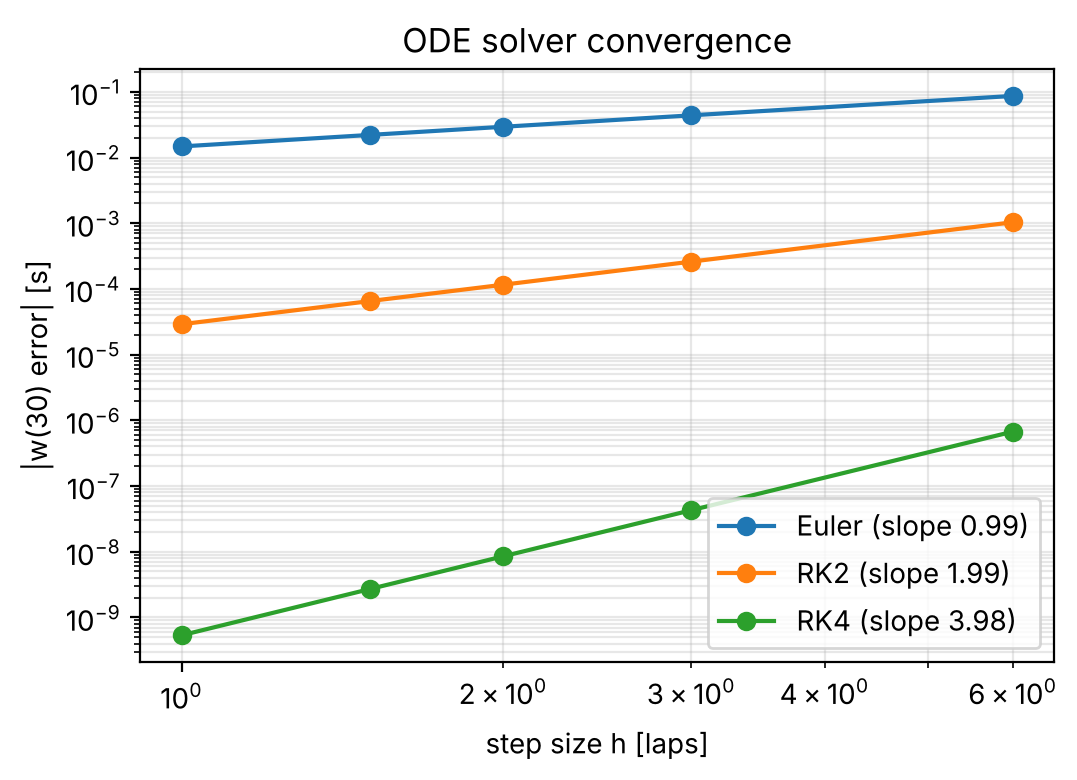

measured orders: {'Euler': np.float64(0.99), 'RK2': np.float64(1.99), 'RK4': np.float64(3.98)}
PASS 5.1


In [14]:
pv = with_params(p, eta_per_s=0.08)          # stronger nonlinearity makes the order study visible
f = wear_rhs(pv, "SOFT", 1, 1.0)
exact = float(wear_closed_form(pv, "SOFT", 1, 30.0))
w_rk4 = float(rk4_solve(f, 0.0, 0.0, 30.0, 30))
print("w(30) exact = %.10f s, RK4 (h=1) = %.10f s, error %.2e s" % (exact, w_rk4, abs(w_rk4 - exact)))
assert abs(w_rk4 - exact) < 1e-8

hs = np.array([6.0, 3.0, 2.0, 1.5, 1.0])
orders = {}
plt.figure(figsize=(5.5, 4))
for name, solver in (("Euler", euler_solve), ("RK2", rk2_solve), ("RK4", rk4_solve)):
    errs = np.array([abs(float(solver(f, 0.0, 0.0, 30.0, int(round(30 / h)))) - exact) for h in hs])
    orders[name] = np.polyfit(np.log(hs), np.log(errs), 1)[0]
    plt.loglog(hs, errs, "o-", label="%s (slope %.2f)" % (name, orders[name]))
plt.xlabel("step size h [laps]"); plt.ylabel("|w(30) error| [s]"); plt.title("ODE solver convergence")
plt.legend(); plt.grid(True, which="both", alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "convergence_ode.png"), dpi=150); plt.show()
print("measured orders:", {k: round(v, 2) for k, v in orders.items()})
assert abs(orders["Euler"] - 1) < 0.3 and abs(orders["RK2"] - 2) < 0.3 and abs(orders["RK4"] - 4) < 0.3
print("PASS 5.1")

### 5.2 Deterministic benchmark with a derived optimum
With all randomness off, linear wear and $P_{GV}=P_{GS}=0$, the simulated race time of every one-stop MEDIUM→HARD strategy must equal the closed form (stint cost $S\Delta_c+k_cS(S-1)/2$ plus pit loss) to $10^{-6}$ s. The best integer pit lap must be $\lfloor L^*\rfloor$ or $\lceil L^*\rceil$ from §3.6, and the one- vs two-stop rule must agree with the simulator.

In [15]:
pd_ = linear_params(p); pd_.update(random=False, p_gv=0.0, p_gs=0.0, p_lap1_sc=0.0)
crew_det = pd_["crew_shift_s"] + math.exp(pd_["crew_mu"])
laps = range(8, 55)
sim = {L: simulate_race(strategy([L], ["MEDIUM", "HARD"]), pd_, 0)["total_time"] for L in laps}
ana = {L: green_total_linear(strategy([L], ["MEDIUM", "HARD"]), pd_) + pd_["dT_green_s"] + crew_det for L in laps}
worst = max(abs(sim[L] - ana[L]) for L in laps)
L_star = optimal_one_stop_lap("MEDIUM", "HARD", pd_)
best = min(sim, key=sim.get)
print("max |sim - analytic| = %.2e s; L* = %.2f; simulated best lap = %d" % (worst, L_star, best))
assert worst < 1e-6
assert best in (math.floor(L_star), math.ceil(L_star))
k_be = two_stop_break_even_k(pd_)
print("Green break-even wear rate for one vs two equal MEDIUM stints: k* = %.4f s/lap (MEDIUM k = %.3f)" % (k_be, pd_["k_s_per_lap"]["MEDIUM"]))
one = simulate_race(strategy([31], ["MEDIUM", "HARD"]), with_params(pd_, k_s_per_lap={"SOFT": .1, "MEDIUM": .06, "HARD": .06}, offset_s={"SOFT": 0, "MEDIUM": 0, "HARD": 0}), 0)["total_time"]
two = simulate_race(strategy([21, 42], ["MEDIUM", "HARD", "MEDIUM"]), with_params(pd_, k_s_per_lap={"SOFT": .1, "MEDIUM": .06, "HARD": .06}, offset_s={"SOFT": 0, "MEDIUM": 0, "HARD": 0}), 0)["total_time"]
assert (two < one) == (0.06 > k_be)
print("PASS 5.2")

max |sim - analytic| = 1.82e-12 s; L* = 26.66; simulated best lap = 27
Green break-even wear rate for one vs two equal MEDIUM stints: k* = 0.0739 s/lap (MEDIUM k = 0.060)
PASS 5.2


### 5.3 Markov chain: validity, stationarity and Safety-Car duration law
Every matrix in the $P_{GS}$ sweep must have non-negative entries and rows summing to 1. A $10^5$-lap run of the expanded chain must reproduce the renewal-reward fractions (§3.4) within 0.01. The simulated SC lengths must never be shorter than $m$, and their mean must match $E[D_S]$ within 3 standard errors.

In [16]:
P_GS_SWEEP = [0.0, 0.005, 0.01, 0.02, 0.03, 0.04, 0.06]
for v in P_GS_SWEEP:
    q = with_params(p, p_gs=v)
    for M in (lumped_matrix(q), expanded_matrix(q)[0]):
        assert M.min() >= 0 and np.allclose(M.sum(1), 1.0)
P, collapse = expanded_matrix(p)
path = collapse[simulate_track_status(P, 100_000, np.random.default_rng(SEED), 0)]
emp = np.bincount(path, minlength=3) / len(path)
pi_renewal = renewal_fractions(p)
pi_eig = np.array([stationary_distribution(P)[collapse == k].sum() for k in range(3)])
print("empirical", emp.round(4), "| renewal formula", pi_renewal.round(4), "| eigen-solve", pi_eig.round(4))
assert np.allclose(pi_renewal, pi_eig, atol=1e-10) and np.max(np.abs(emp - pi_renewal)) < 0.01
runs, n = [], 0
for s in path:
    if s == SC: n += 1
    elif n: runs.append(n); n = 0
runs = np.array(runs)
se = runs.std(ddof=1) / math.sqrt(len(runs))
print("SC periods: %d, min length %d laps (m = %d), mean %.3f laps vs E[D] = %.3f" % (len(runs), runs.min(), p["sc_min_laps"], runs.mean(), sc_mean_duration(p)))
assert runs.min() >= p["sc_min_laps"] and abs(runs.mean() - sc_mean_duration(p)) < 3 * se
m_hat, pss_hat = mle_sc_persistence(runs)
print("MLE recovers m = %d, p_SS = %.3f (true %.2f)" % (m_hat, pss_hat, p["p_ss"]))
assert m_hat == p["sc_min_laps"] and abs(pss_hat - p["p_ss"]) < 0.03
print("PASS 5.3")

empirical [0.902  0.0262 0.0718] | renewal formula [0.9009 0.027  0.0721] | eigen-solve [0.9009 0.027  0.0721]
SC periods: 1777, min length 3 laps (m = 3), mean 4.043 laps vs E[D] = 4.000
MLE recovers m = 3, p_SS = 0.511 (true 0.50)
PASS 5.3


### 5.4 Exact expected race time vs Monte Carlo (independent check of the whole stochastic pipeline)
In the analytically tractable case ($\eta=\beta=0$, $\varphi=1$), the exact expectation from §3.6 uses only matrix powers of the chain. The Monte Carlo mean from 40,000 races must lie within 3 standard errors of it, for every strategy and for three values of $P_{GS}$.

In [17]:
check_strats = [strategy([26], ["MEDIUM", "HARD"]), strategy([18, 40], ["SOFT", "MEDIUM", "HARD"])]
for v in (0.0, 0.02, 0.05):
    q = linear_params(with_params(p, p_gs=v))
    X = run_paired(check_strats, q, 40_000, SEED + 1)
    for j, s in enumerate(check_strats):
        ex = exact_expected_total(s, q)
        se = X[:, j].std(ddof=1) / math.sqrt(len(X))
        print("P_GS=%.2f %-22s exact %.3f s | MC %.3f s | z = %+.2f" % (v, s["name"], ex, X[:, j].mean(), (X[:, j].mean() - ex) / se))
        assert abs(X[:, j].mean() - ex) < 3 * se
print("PASS 5.4")

P_GS=0.00 1-stop M-H @26         exact 6241.418 s | MC 6241.410 s | z = -0.01
P_GS=0.00 2-stop S-M-H @18,40    exact 6250.023 s | MC 6250.012 s | z = -0.02


P_GS=0.02 1-stop M-H @26         exact 6469.432 s | MC 6468.593 s | z = -0.70
P_GS=0.02 2-stop S-M-H @18,40    exact 6478.426 s | MC 6477.585 s | z = -0.70


P_GS=0.05 1-stop M-H @26         exact 6757.937 s | MC 6757.883 s | z = -0.04
P_GS=0.05 2-stop S-M-H @18,40    exact 6767.426 s | MC 6767.374 s | z = -0.03
PASS 5.4


### 5.5 Conservation, limiting cases and model rules
These checks confirm that:
* every race has 62 laps and its total equals the sum of its laps;
* fuel never goes negative;
* tyre age resets at each stop;
* the stationary time is added unscaled, and only net transit is reduced by $(1-\alpha_s)$;
* $\alpha=0$ makes neutralised stops cost the same as Green stops;
* identical strategies under CRN differ by exactly 0;
* single-compound and out-of-range strategies are rejected;
* the loop and vectorised implementations agree to $10^{-9}$ s.

In [18]:
s1 = strategy([26], ["MEDIUM", "HARD"])
r = simulate_race(s1, p, SEED)
assert len(r["lap_times"]) == p["n_laps"] and abs(r["total_time"] - r["lap_times"].sum()) < 1e-9
assert r["fuel_kg"].min() >= 0 and np.all(np.diff(r["fuel_kg"]) <= 0)
assert r["tyre_age"][r["pit_laps"][0]] == 0
for st, a in ((VSC, p["alpha_vsc"]), (SC, p["alpha_sc"])):
    assert abs((pit_loss(st, 2.5, p) - 2.5) - (1 - a) * (pit_loss(GREEN, 2.5, p) - 2.5)) < 1e-12
q0 = with_params(p, alpha_vsc=0.0, alpha_sc=0.0)
assert pit_loss(SC, 2.5, q0) == pit_loss(GREEN, 2.5, q0)
X = run_paired([s1, s1], p, 500, SEED)
assert np.max(np.abs(X[:, 0] - X[:, 1])) == 0
assert not validate_strategy(strategy([26], ["HARD", "HARD"]), p)
assert not validate_strategy(strategy([70], ["SOFT", "HARD"]), p)
scen = draw_scenarios(200, p, SEED)
s3 = strategy([30], ["MEDIUM", "HARD"], reactive_window=(14, 30))
assert np.max(np.abs(simulate_scenarios(s3, p, scen) - [simulate_race_loop(s3, p, scen, i) for i in range(200)])) < 1e-9
print("PASS 5.5")

PASS 5.5


### 5.6 Random variate generators (Kolmogorov–Smirnov)
Box–Muller output must be N(0,1), and crew times must follow the shifted lognormal. Each KS statistic must be below the 5% critical value $1.36/\sqrt n$, and no crew time may fall below the shift.

In [19]:
def ks_stat(x, cdf):
    # One-sample Kolmogorov-Smirnov statistic D_n
    x = np.sort(np.asarray(x)); n = len(x); F = cdf(x)
    return max(np.max(np.arange(1, n + 1) / n - F), np.max(F - np.arange(n) / n))

norm_cdf = np.vectorize(lambda v: 0.5 * (1 + math.erf(v / math.sqrt(2))))
rng = np.random.default_rng(SEED + 2)
z = box_muller(5000, rng)
c = sample_crew_time(5000, p, rng)
shift, mu, sg = crew_time_params(p)
D_z = ks_stat(z, norm_cdf)
D_c = ks_stat(c, lambda v: norm_cdf((np.log(v - shift) - mu) / sg))
crit = 1.36 / math.sqrt(5000)
print("Box-Muller: mean %.3f sd %.3f KS D %.4f | crew: min %.3f s, mean %.3f s (theory %.3f s), KS D %.4f | critical %.4f"
      % (z.mean(), z.std(), D_z, c.min(), c.mean(), shift + math.exp(mu + sg**2 / 2), D_c, crit))
assert D_z < crit and D_c < crit and c.min() > shift
print("PASS 5.6")

Box-Muller: mean 0.009 sd 1.006 KS D 0.0100 | crew: min 2.118 s, mean 2.675 s (theory 2.680 s), KS D 0.0123 | critical 0.0192
PASS 5.6


### 5.7 Monte Carlo error falls as $N^{-1/2}$
The standard deviation of the mean race time across 30 independent batches is fitted on a log–log scale. The expected slope is −0.5 ± 0.15.

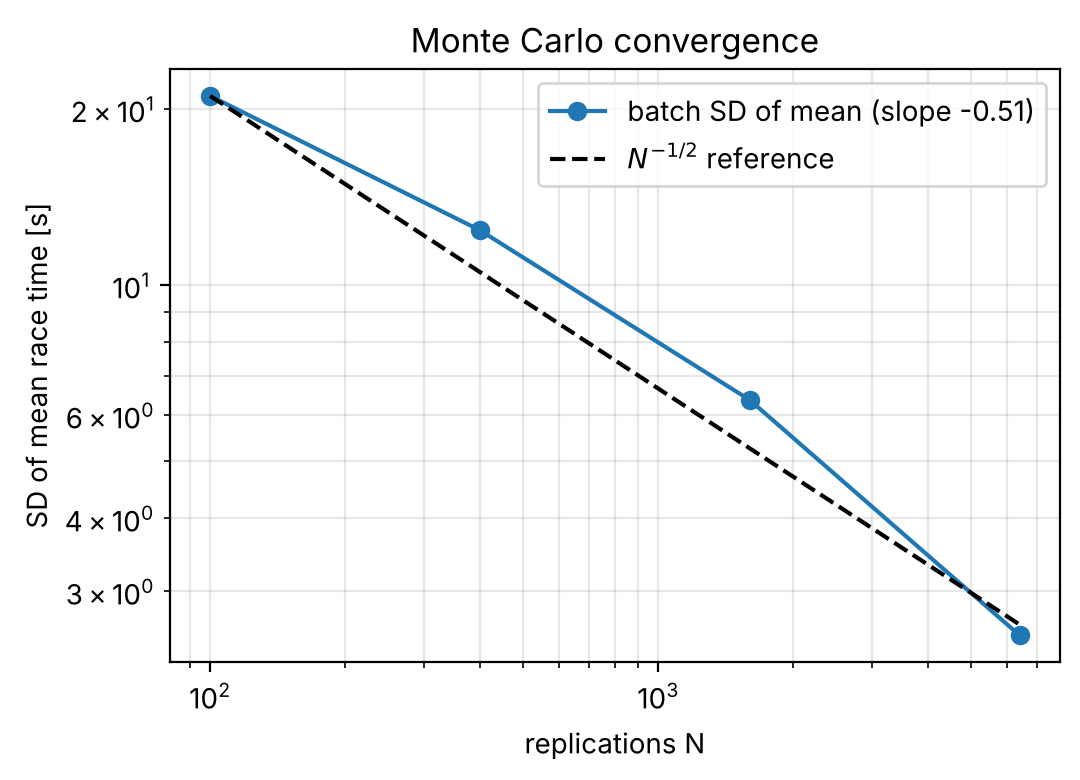

PASS 5.7 (slope -0.507)


In [20]:
Ns = np.array([100, 400, 1600, 6400])
sds = [np.std([run_paired([s1], p, n, SEED + 1000 * j + n)[:, 0].mean() for j in range(30)], ddof=1) for n in Ns]
slope = np.polyfit(np.log(Ns), np.log(sds), 1)[0]
plt.figure(figsize=(5.5, 4)); plt.loglog(Ns, sds, "o-", label="batch SD of mean (slope %.2f)" % slope)
plt.loglog(Ns, sds[0] * np.sqrt(Ns[0] / Ns), "k--", label=r"$N^{-1/2}$ reference")
plt.xlabel("replications N"); plt.ylabel("SD of mean race time [s]"); plt.title("Monte Carlo convergence")
plt.legend(); plt.grid(True, which="both", alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "convergence_mc.png"), dpi=150); plt.show()
assert abs(slope + 0.5) < 0.15
print("PASS 5.7 (slope %.3f)" % slope)

## 6. Experiments and results

### 6.1 Stage 1: screening (1,000 common scenarios)
All legal one-stop and two-stop windows on the grid are screened, together with *pit-if-neutralised* variants of the one-stops: plan to stop at lap $L$, but stop earlier at the first VSC/SC between lap 12 and $L$. Shortlist rule, fixed in advance: the best one-stop, the best two-stop and the best reactive strategy.

In [21]:
SEED_STAGE1, SEED_STAGE2 = SEED + 11, SEED + 22          # independent stages (H13)
cands = candidate_strategies(p)
cands += [strategy([L], c, reactive_window=(12, L)) for c in (("MEDIUM", "HARD"), ("HARD", "MEDIUM")) for L in range(20, 46, 2)]
t0 = time.perf_counter()
ranked = screen(cands, p, 1000, SEED_STAGE1)
print("screened %d strategies in %.1f s" % (len(cands), time.perf_counter() - t0))
def best_of(pred):
    return next(s for m, s in ranked if pred(s))
best1 = best_of(lambda s: len(s["pit_laps"]) == 1 and s["reactive_window"] is None)
best2 = best_of(lambda s: len(s["pit_laps"]) == 2)
bestR = best_of(lambda s: s["reactive_window"] is not None)
for m, s in ranked[:8]:
    print("  %.1f s  %s" % (m, s["name"]))
SHORTLIST = [best1, best2, bestR]
print("Shortlist:", [s["name"] for s in SHORTLIST])

screened 272 strategies in 1.2 s
  6477.5 s  1-stop H-M @34
  6477.6 s  1-stop H-M @36
  6477.9 s  1-stop M-H @28 react[12-28]
  6477.9 s  1-stop H-M @32
  6477.9 s  1-stop M-H @26 react[12-26]
  6477.9 s  1-stop H-M @38
  6478.1 s  1-stop M-H @24 react[12-24]
  6478.1 s  1-stop M-H @30 react[12-30]
Shortlist: ['1-stop H-M @34', '2-stop M-H-S @19,46', '1-stop M-H @28 react[12-28]']


### 6.2 Stage 2: 10,000 fresh scenarios, paired 95% CIs (Bonferroni-adjusted)
Differences are relative to the best one-stop. With 2 comparisons, Bonferroni uses $z_{1-0.05/4}$.

In [22]:
z_b = bonferroni_z(2)
rows, X2 = paired_table(SHORTLIST, p, 10_000, SEED_STAGE2, ref=0, z=z_b)
print("Bonferroni z = %.3f, N = 10,000\n" % z_b)
print("%-34s %12s %22s %24s" % ("strategy", "mean [s]", "CI [s]", "diff vs 1-stop [s]"))
for r_ in rows:
    print("%-34s %12.2f   [%9.2f, %9.2f]   %+7.2f [%+.2f, %+.2f]" % (r_["name"], r_["mean_s"], r_["ci_low_s"], r_["ci_high_s"], r_["diff_s"], r_["diff_low_s"], r_["diff_high_s"]))
vr = variance_reduction_ratio(best1, best2, p, 10_000, SEED + 33)
print("\nCRN variance reduction (independent / paired variance of the 2-stop minus 1-stop difference): %.1fx" % vr)
sd_D = np.std(X2[:, 1] - X2[:, 0], ddof=1)
print("Sample size for a +/-0.25 s half-width: n >= (z s_D / h)^2 = %.0f (we use 10,000)" % ((z_b * sd_D / 0.25) ** 2))

Bonferroni z = 2.241, N = 10,000

strategy                               mean [s]                 CI [s]       diff vs 1-stop [s]
1-stop H-M @34                          6478.52   [  6473.19,   6483.86]     +0.00 [+0.00, +0.00]
2-stop M-H-S @19,46                     6486.07   [  6480.70,   6491.43]     +7.54 [+7.44, +7.65]
1-stop M-H @28 react[12-28]             6479.03   [  6473.70,   6484.36]     +0.50 [+0.40, +0.61]



CRN variance reduction (independent / paired variance of the 2-stop minus 1-stop difference): 5127.8x
Sample size for a +/-0.25 s half-width: n >= (z s_D / h)^2 = 1769 (we use 10,000)


### 6.3 How the answer changes with the SC onset probability $P_{GS}$
For each $P_{GS}$ in the sweep, 10,000 fresh common scenarios give paired differences (two-stop − one-stop, reactive − one-stop) with 95% CIs. The crossover is the $P_{GS}$ at which a difference changes sign (linear interpolation of the means). We also sweep $\alpha_{SC}$ at the baseline $P_{GS}$.

two-stop − one-stop              0.000:+6.51[+6.47,+6.56] 0.005:+6.68[+6.62,+6.74] 0.010:+6.98[+6.91,+7.05] 0.020:+7.48[+7.39,+7.57] 0.030:+7.92[+7.81,+8.02] 0.040:+8.42[+8.30,+8.53] 0.060:+9.08[+8.95,+9.21]
pit-if-neutralised − one-stop    0.000:+1.23[+1.18,+1.28] 0.005:+0.98[+0.92,+1.04] 0.010:+0.76[+0.69,+0.84] 0.020:+0.44[+0.36,+0.53] 0.030:+0.06[-0.04,+0.16] 0.040:+0.04[-0.06,+0.14] 0.060:-0.41[-0.52,-0.31]


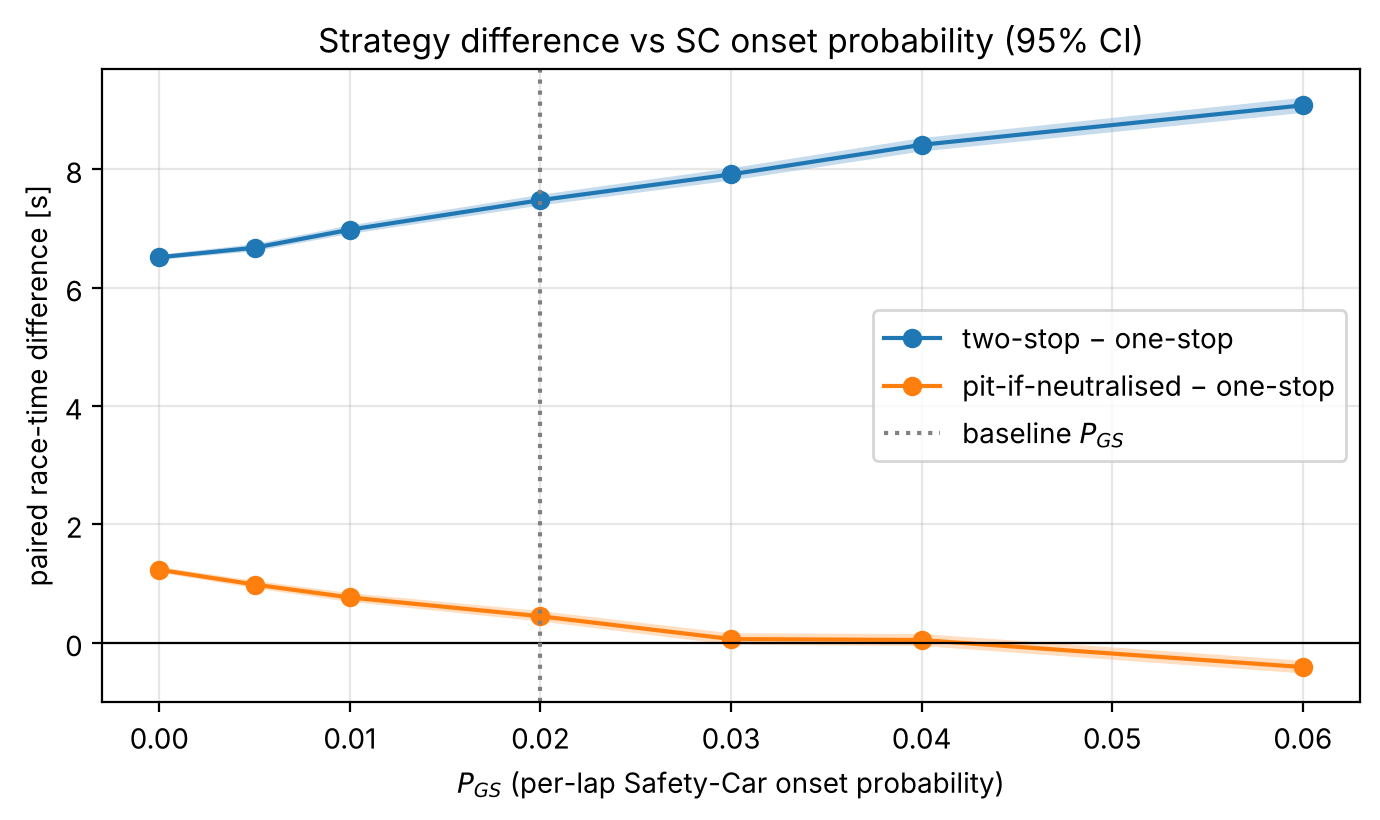

crossover (two-stop − one-stop): none in the swept range
crossover (pit-if-neutralised − one-stop): P_GS ~ 0.0419


In [23]:
sweep = []
for v in P_GS_SWEEP:
    q = with_params(p, p_gs=v)
    X = run_paired(SHORTLIST, q, 10_000, SEED + 100 + int(v * 1e4))
    sweep.append([v] + [mean_ci(X[:, j] - X[:, 0]) for j in (1, 2)])
def crossover(xs, ys):
    # first P_GS where the mean difference changes sign (linear interpolation)
    for x0, y0, x1, y1 in zip(xs, ys, xs[1:], ys[1:]):
        if y0 == 0:
            return x0
        if y0 * y1 < 0:
            return x0 + (x1 - x0) * y0 / (y0 - y1)
    return None
fig, ax = plt.subplots(figsize=(7, 4.2))
cross = {}
for j, lab in ((1, "two-stop − one-stop"), (2, "pit-if-neutralised − one-stop")):
    m = np.array([row[j][0] for row in sweep]); lo = np.array([row[j][1] for row in sweep]); hi = np.array([row[j][2] for row in sweep])
    ax.plot(P_GS_SWEEP, m, "o-", label=lab); ax.fill_between(P_GS_SWEEP, lo, hi, alpha=.25)
    cross[lab] = crossover(P_GS_SWEEP, m)
    print("%-32s" % lab, " ".join("%.3f:%+.2f[%+.2f,%+.2f]" % (v, a, b, c) for v, (a, b, c) in zip(P_GS_SWEEP, [row[j] for row in sweep])))
ax.axhline(0, color="k", lw=.8); ax.axvline(p["p_gs"], color="grey", ls=":", label="baseline $P_{GS}$")
ax.set_xlabel("$P_{GS}$ (per-lap Safety-Car onset probability)"); ax.set_ylabel("paired race-time difference [s]")
ax.set_title("Strategy difference vs SC onset probability (95% CI)"); ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "results_pgs_sweep.png"), dpi=150); plt.show()
for k, v in cross.items():
    print("crossover (%s): %s" % (k, "P_GS ~ %.4f" % v if v is not None else "none in the swept range"))

### 6.4 Sensitivity analysis (which inputs drive the answer?)
One-at-a-time sweeps of $P_{GS}$, $\alpha_{SC}$, minimum SC length $m$, crew-time spread $\sigma_C$ and the HARD wear rate. The reported quantity is the headline paired difference (two-stop − one-stop) with its 95% CI (4,000 common scenarios per point).

p_gs         range of mean difference: +6.50 .. +9.15 s (swing 2.65 s)
alpha_sc     range of mean difference: +7.46 .. +7.85 s (swing 0.39 s)
sc_min_laps  range of mean difference: +7.21 .. +7.92 s (swing 0.71 s)
crew_sigma   range of mean difference: +7.60 .. +7.79 s (swing 0.19 s)
k_hard       range of mean difference: +3.69 .. +10.27 s (swing 6.58 s)


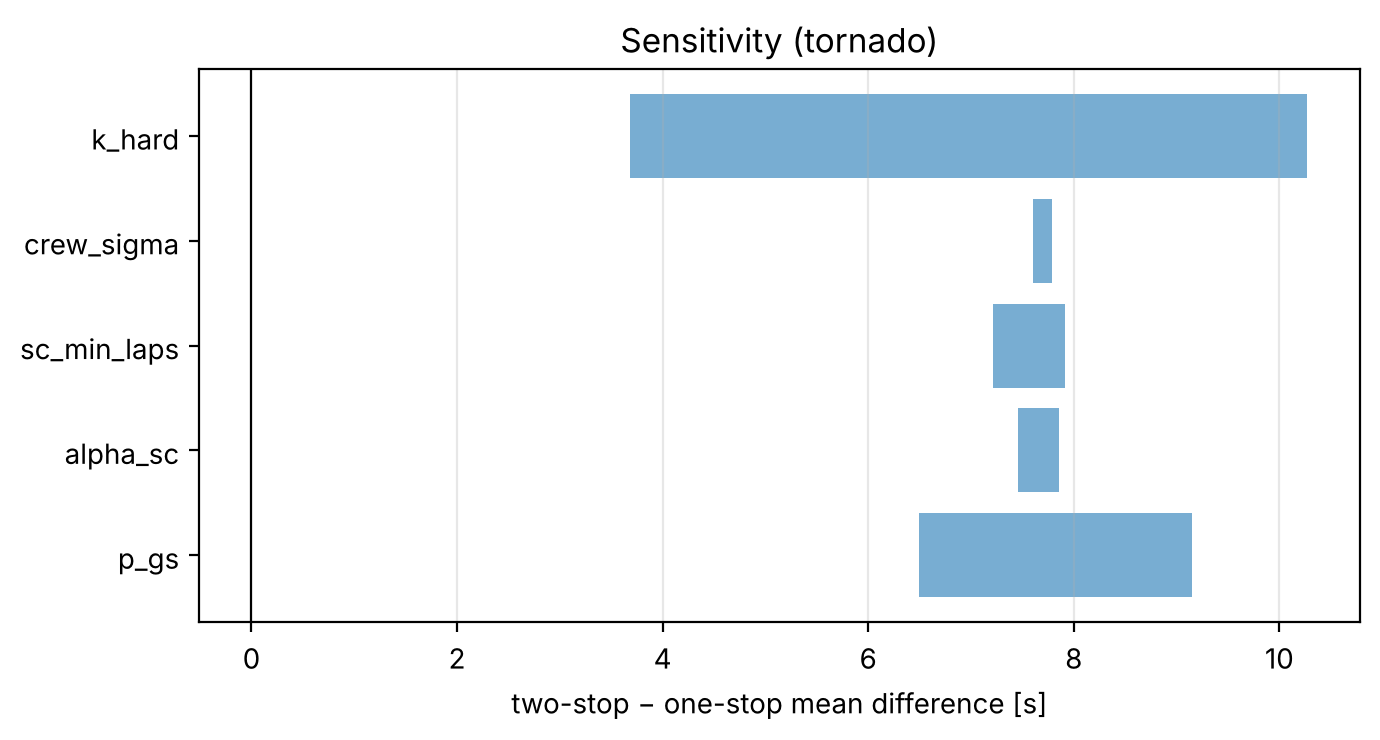

In [24]:
SENS = {
    "p_gs":        [0.0, 0.02, 0.04, 0.06],
    "alpha_sc":    [0.25, 0.43, 0.60],
    "sc_min_laps": [2, 3, 4],
    "crew_sigma":  [0.3, 0.5, 0.8],
    "k_hard":      [0.025, 0.035, 0.050],
}
sens_rows = []
for name, values in SENS.items():
    for v in values:
        if name == "alpha_sc":
            q = with_params(p, alpha_sc=v, alpha_vsc=p["alpha_vsc"])
        elif name == "k_hard":
            ks = dict(p["k_s_per_lap"]); ks["HARD"] = v; q = with_params(p, k_s_per_lap=ks)
        else:
            q = with_params(p, **{name: v})
        X = run_paired(SHORTLIST[:2], q, 4000, SEED + 500)
        m, lo, hi = mean_ci(X[:, 1] - X[:, 0])
        sens_rows.append(dict(param=name, value=v, mean_diff_s=m, ci_low_s=lo, ci_high_s=hi))
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, name in enumerate(SENS):
    rr = [r_ for r_ in sens_rows if r_["param"] == name]
    lo_, hi_ = min(r_["mean_diff_s"] for r_ in rr), max(r_["mean_diff_s"] for r_ in rr)
    ax.barh(i, hi_ - lo_, left=lo_, color="C0", alpha=.6)
    print("%-12s range of mean difference: %+.2f .. %+.2f s (swing %.2f s)" % (name, lo_, hi_, hi_ - lo_))
ax.set_yticks(range(len(SENS))); ax.set_yticklabels(list(SENS)); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("two-stop − one-stop mean difference [s]"); ax.set_title("Sensitivity (tornado)"); ax.grid(alpha=.3, axis="x")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "sensitivity_tornado.png"), dpi=150); plt.show()

### 6.5 Performance: plain loop vs vectorised NumPy
The same 2,000 scenarios are run through the per-race Python loop and the vectorised simulator. The results must be identical, and the timings are the median of 3 runs.

In [25]:
scen = draw_scenarios(2000, p, SEED + 7)
t_loop, a = timed(lambda: np.array([simulate_race_loop(best1, p, scen, i) for i in range(2000)]))
t_vec, b = timed(lambda: simulate_scenarios(best1, p, scen))
assert np.max(np.abs(a - b)) < 1e-9
print("loop %.3f s | vectorised %.4f s | speed-up %.1fx (identical results)" % (t_loop, t_vec, t_loop / t_vec))

loop 0.242 s | vectorised 0.0062 s | speed-up 39.0x (identical results)


## 7. Discussion and limitations

*The numbers below come from the run above. Re-read them after changing parameters.*

In [26]:
print("Answer to the question (baseline P_GS = %.3f):" % p["p_gs"])
for r_ in rows[1:]:
    verdict = "faster" if r_["diff_high_s"] < 0 else ("slower" if r_["diff_low_s"] > 0 else "not distinguishable")
    print("  %-34s %+.2f s [%+.2f, %+.2f] vs best one-stop -> %s" % (r_["name"], r_["diff_s"], r_["diff_low_s"], r_["diff_high_s"], verdict))
for k, v in cross.items():
    print("  switch point (%s): %s" % (k, "P_GS ~ %.4f" % v if v is not None else "none within P_GS in [0, 0.06]"))
print("  CRN variance reduction: %.1fx" % vr)

Answer to the question (baseline P_GS = 0.020):
  2-stop M-H-S @19,46                +7.54 s [+7.44, +7.65] vs best one-stop -> slower
  1-stop M-H @28 react[12-28]        +0.50 s [+0.40, +0.61] vs best one-stop -> slower
  switch point (two-stop − one-stop): none within P_GS in [0, 0.06]
  switch point (pit-if-neutralised − one-stop): P_GS ~ 0.0419
  CRN variance reduction: 5127.8x


**Interpretation (baseline run, master seed 20251005; re-check the printed numbers if you change parameters).**
* **Fixed windows gain little from safety cars.** A planned stop falls under SC only with probability $p_S(L)$, a few percent per lap, so the expected discount per stop is small (§3.6). The stage-2 table shows the best one-stop ahead of the best two-stop by several seconds, with a CI far from zero.
* **More safety cars make the two-stop *worse*, not better.** SC laps cheapen stops (via $\alpha_{SC}$), but they also replace Green laps, where degradation costs time, and they slow tyre wear ($\varphi_S$). Fresh tyres are therefore worth less, and in this model the second effect dominates. So the two-stop never overtakes the one-stop in the swept range.
* **The value of an SC comes from reacting to it.** The pit-if-neutralised strategy's gap to the one-stop shrinks steadily as $P_{GS}$ grows. It crosses zero at the printed switch point, about twice the baseline onset rate.
* **What drives the answer:** the HARD wear rate and $P_{GS}$ dominate the tornado chart, while $\alpha_{SC}$ and the crew-time spread barely matter. Tyre wear is therefore the first parameter to calibrate with FastF1.
* **CRN is extremely effective here:** under H6, SC laps are identical for all strategies, so they cancel. The measured variance ratio is in the thousands, far beyond the ≥ 2 a generic model would give.

**Limitations.**
1. Single car: no track position, overtaking or traffic. At Singapore, track position matters a lot, and this model ignores it.
2. The objective is expected race time, not finishing position or points.
3. Parameters marked *assumed* (wear rates, pit geometry, crew spread) still need calibration with FastF1 data (`src/calibrate.py`).
4. A time-homogeneous incident rate after lap 1, and no VSC→SC escalation.
5. Pit losses assume the 2025 80 km/h pit-lane limit.
6. No weather, red flags, or slow-stop / unsafe-release events.
7. Only about six Singapore races exist in FastF1, so $P_{GS}$ is uncertain. Hence the sweep and the sensitivity study.

**With more time:** calibrate from FastF1, add a Bellman (dynamic-programming) optimal reactive policy, and extend to the two-car team model.

## 8. References
[1] A. Heilmeier, M. Graf, J. Betz and M. Lienkamp, "Application of Monte Carlo methods to consider probabilistic effects in a race simulation for circuit motorsport," *Appl. Sci.*, vol. 10, no. 12, 4229, 2020, doi: 10.3390/app10124229.
[2] A. Heilmeier, A. Thomaser, M. Graf and J. Betz, "Virtual Strategy Engineer: Using artificial neural networks for making race strategy decisions in circuit motorsport," *Appl. Sci.*, vol. 10, no. 21, 7805, 2020, doi: 10.3390/app10217805.
[3] J. Bekker and W. Lotz, "Planning Formula One race strategies using discrete-event simulation," *J. Oper. Res. Soc.*, vol. 60, no. 7, pp. 952–961, 2009.
[4] T. Tulabandhula and C. Rudin, "Tire changes, fresh air, and yellow flags: Challenges in predictive analytics for professional racing," *Big Data*, vol. 2, no. 2, pp. 97–112, 2014, doi: 10.1089/big.2014.0018.
[5] A. M. Law, *Simulation Modeling and Analysis*, 5th ed. McGraw-Hill, 2015.
[6] P. Glasserman, *Monte Carlo Methods in Financial Engineering*. Springer, 2003.
[7] FastF1 documentation. https://docs.fastf1.dev/
[8] GPblog, "Pit lane speed limit raised in Singapore for strategy options," Oct. 2025.
[9] Lights Out Blog, "Every Safety Car deployment at the Singapore Grand Prix."